In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# File and directory handling
from pathlib import Path
import os

# Image processing
from PIL import Image, ImageOps

# Data splitting
from sklearn.model_selection import train_test_split

# Deep learning
import tensorflow as tf

# MobileNetV2 preprocessing
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Visualization
import matplotlib.pyplot as plt

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Define project directory
PROJECT_DIR = Path.cwd().parent

# Define dataset directory
DATASET_DIR = PROJECT_DIR / "dataset"

# Define CSV file path
CSV_PATH = DATASET_DIR / "train.csv"

# Define retinal images directory
IMAGE_DIR = DATASET_DIR / "train_images"

# Load CSV dataset
df = pd.read_csv(CSV_PATH)

print("Dataset loaded successfully!")

print("\nDataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset loaded successfully!

Dataset shape: (3662, 2)

First five records:


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3662 entries, 0 to 3661
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id_code    3662 non-null   str  
 1   diagnosis  3662 non-null   int64
dtypes: int64(1), str(1)
memory usage: 57.3 KB


Data Verification

In [3]:
# Check whether CSV exists
print("CSV exists:", CSV_PATH.exists())

# Check whether image directory exists
print("Image directory exists:", IMAGE_DIR.exists())

# Count dataset records
print("Total CSV records:", len(df))

# Count image files
image_count = len(list(IMAGE_DIR.glob("*.png")))

print("Total retinal images:", image_count)

# Check columns
print("\nDataset columns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

CSV exists: True
Image directory exists: True
Total CSV records: 3662
Total retinal images: 3662

Dataset columns:
['id_code', 'diagnosis']

Missing values:
id_code      0
diagnosis    0
dtype: int64


In [4]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("TensorFlow location:", tf.__file__)

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("MobileNetV2 preprocessing imported successfully!")

TensorFlow version: 2.21.0
TensorFlow location: c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\.venv\Lib\site-packages\tensorflow\__init__.py
MobileNetV2 preprocessing imported successfully!


In [5]:
# Split dataset into training and validation sets

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["diagnosis"]
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# Display dataset sizes
print("Training images:", len(train_df))
print("Validation images:", len(val_df))

# Display class distributions
print("\nTraining class distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_df["diagnosis"].value_counts().sort_index())

Training images: 2929
Validation images: 733

Training class distribution:
diagnosis
0    1444
1     296
2     799
3     154
4     236
Name: count, dtype: int64

Validation class distribution:
diagnosis
0    361
1     74
2    200
3     39
4     59
Name: count, dtype: int64


Image preprocessing using Tensorflow

Our objective is to convert every retinal image into a format suitable for MobileNetV2.

We will perform five operations:
1. Read the image.
2. Decode the PNG file.
3. Convert it into RGB format.
4. Resize it to 224 × 224 while preserving its aspect ratio.
5. Apply MobileNetV2 normalization.

In [6]:
IMG_SIZE = 224
print("Target image height : ",IMG_SIZE)
print("Target image width : ",IMG_SIZE)

Target image height :  224
Target image width :  224


In [7]:
def load_and_preprocess(image_path, label):

    # Step 1: Read image file
    image = tf.io.read_file(image_path)

    # Step 2: Decode PNG image and convert to RGB
    image = tf.image.decode_png(
        image,
        channels=3
    )

    # Step 3: Convert image to float32
    image = tf.cast(image, tf.float32)

    # Step 4: Resize image while preserving aspect ratio
    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_SIZE,
        target_width=IMG_SIZE,
        method="bilinear",
        antialias=True
    )

    # Step 5: Apply MobileNetV2 preprocessing
    image = preprocess_input(image)

    # Step 6: Convert label to integer
    label = tf.cast(label, tf.int32)

    return image, label

Testing image preprocessing on a sample image

In [8]:
# Select one image from training dataset

sample_id = train_df.loc[0, "id_code"]

sample_path = str(
    IMAGE_DIR / f"{sample_id}.png"
)

sample_label = train_df.loc[0, "diagnosis"]


# Apply preprocessing

processed_image, processed_label = load_and_preprocess(
    sample_path,
    sample_label
)


# Display output information

print("Image ID:", sample_id)

print("Processed image shape:", processed_image.shape)

print("Image data type:", processed_image.dtype)

print("Diagnosis label:", processed_label.numpy())

print(
    "Minimum pixel value:",
    tf.reduce_min(processed_image).numpy()
)

print(
    "Maximum pixel value:",
    tf.reduce_max(processed_image).numpy()
)

Image ID: b2b79b37d314
Processed image shape: (224, 224, 3)
Image data type: <dtype: 'float32'>
Diagnosis label: 0
Minimum pixel value: -1.0
Maximum pixel value: 1.0


Visualising the processed image

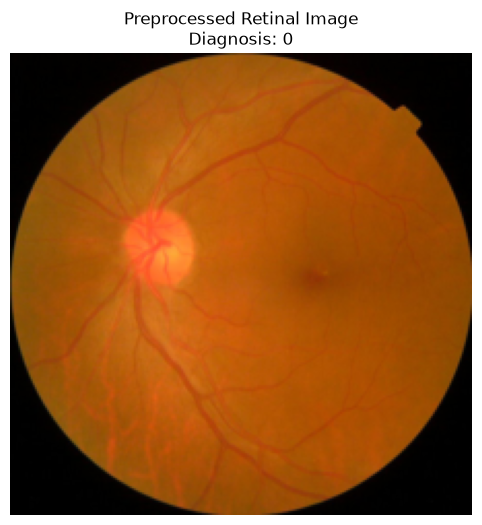

In [9]:
# Convert normalized image back to display range

display_image = (
    processed_image.numpy() + 1.0
) / 2.0

display_image = np.clip(display_image, 0, 1)


# Display image

plt.figure(figsize=(6, 6))

plt.imshow(display_image)

plt.title(
    f"Preprocessed Retinal Image\nDiagnosis: {processed_label.numpy()}"
)

plt.axis("off")

plt.show()

In [10]:
#Defining batch size for tensorflow data pipeline
BATCH_SIZE = 8
print("Batch size : ",BATCH_SIZE)

Batch size :  8


Creating Tensorflow dataset function

In [11]:
def create_dataset(dataframe, training=False):

    # Step 1: Generate image file paths
    image_paths = [
        str(IMAGE_DIR / f"{image_id}.png")
        for image_id in dataframe["id_code"]
    ]

    # Step 2: Extract diagnosis labels
    labels = dataframe["diagnosis"].values.astype("int32")

    # Step 3: Create TensorFlow dataset
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    # Step 4: Shuffle training data
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    # Step 5: Apply image preprocessing
    dataset = dataset.map(
        load_and_preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Step 6: Divide data into batches
    dataset = dataset.batch(BATCH_SIZE)

    # Step 7: Prefetch data for better performance
    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

Creating Training and Validation dataset

In [12]:
# Create training dataset

train_ds = create_dataset(
    train_df,
    training=True
)


# Create validation dataset

val_ds = create_dataset(
    val_df,
    training=False
)


print("Training dataset created successfully!")
print("Validation dataset created successfully!")

Training dataset created successfully!
Validation dataset created successfully!


Checking dataset structure

In [13]:
print("Training dataset structure:")
print(train_ds.element_spec)

print("\nValidation dataset structure:")
print(val_ds.element_spec)

Training dataset structure:
(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))

Validation dataset structure:
(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


Checking the first training batch

In [14]:
for images, labels in train_ds.take(1):

    print("Training batch shape:", images.shape)

    print("Training labels shape:", labels.shape)

    print("Data type:", images.dtype)

    print(
        "Minimum pixel value:",
        tf.reduce_min(images).numpy()
    )

    print(
        "Maximum pixel value:",
        tf.reduce_max(images).numpy()
    )

    print("Labels:", labels.numpy())

Training batch shape: (8, 224, 224, 3)
Training labels shape: (8,)
Data type: <dtype: 'float32'>
Minimum pixel value: -1.0
Maximum pixel value: 1.0000007
Labels: [0 2 0 0 3 0 4 3]


Checking number of batches

In [15]:
train_batches = tf.data.experimental.cardinality(
    train_ds
).numpy()

val_batches = tf.data.experimental.cardinality(
    val_ds
).numpy()

print("Training batches:", train_batches)
print("Validation batches:", val_batches)

Training batches: 367
Validation batches: 92


In [16]:
import os
print(os.getpid())

21912


In [17]:
train_df.to_csv(DATASET_DIR / "train_split.csv", index=False)
val_df.to_csv(DATASET_DIR / "val_split.csv", index=False)

print("Train and validation splits saved successfully!")

Train and validation splits saved successfully!
